In [2]:
import re
import time
import warnings
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
data = [
    ('The delivery was fast and the food was fresh', 'positive'),
    ('Excellent product quality and friendly support', 'positive'),
    ('The app is easy to use and works perfectly', 'positive'),
    ('Good value for money and quick service', 'positive'),
    ('I am happy with the purchase', 'positive'),
    ('The package arrived early and safely', 'positive'),
    ('Great quality, I would recommend this', 'positive'),
    ('Customer service solved my issue quickly', 'positive'),
    ('The food tasted delicious and fresh', 'positive'),
    ('Everything was perfect and convenient', 'positive'),
    ('The delivery was late but the product quality was excellent', 'mixed'),
    ('The price is high but the quality is good', 'mixed'),
    ('Support was helpful although the app crashed', 'mixed'),
    ('The food was tasty but arrived cold', 'mixed'),
    ('Good packaging, poor delivery timing', 'mixed'),
    ('The product works well but setup was difficult', 'mixed'),
    ('The service was slow but the staff were polite', 'mixed'),
    ('Quality is excellent while the cost is disappointing', 'mixed'),
    ('The app looks nice but it is difficult to navigate', 'mixed'),
    ('Delivery was quick but the item was damaged', 'mixed'),
    ('The delivery was very late', 'negative'),
    ('Poor quality and disappointing experience', 'negative'),
    ('The app keeps crashing and losing my data', 'negative'),
    ('Customer support never answered my question', 'negative'),
    ('The food was cold and tasteless', 'negative'),
    ('Too expensive for such low quality', 'negative'),
    ('The package was damaged when it arrived', 'negative'),
    ('I am unhappy with this service', 'negative'),
    ('The product stopped working after one day', 'negative'),
    ('Terrible experience and no refund', 'negative'),
    ('Fast delivery and excellent quality', 'positive'),
    ('Really useful app with a clean design', 'positive'),
    ('The staff were kind and professional', 'positive'),
    ('Affordable price and reliable performance', 'positive'),
    ('Fresh ingredients and generous portions', 'positive'),
    ('My order arrived on time', 'positive'),
    ('The refund process was smooth and easy', 'positive'),
    ('The website is responsive and simple', 'positive'),
    ('The product exceeded my expectations', 'positive'),
    ('Very satisfied with the overall service', 'positive'),
    ('The service was okay, nothing special', 'neutral'),
    ('It arrived yesterday and looks normal', 'neutral'),
    ('The product is available in three sizes', 'neutral'),
    ('I contacted support about my account', 'neutral'),
    ('The package contains two items', 'neutral'),
    ('The app has a search option', 'neutral'),
    ('My order number is shown in the account', 'neutral'),
    ('The meal includes rice and vegetables', 'neutral'),
    ('The delivery status changed this morning', 'neutral'),
    ('I received the product as described', 'neutral'),
    ('Although the delivery was delayed twice, the support agent apologized and the replacement item was excellent', 'mixed'),
    ('I expected premium quality, yet the item feels fragile and the price is unusually high', 'negative'),
    ('The application is visually attractive, but navigation becomes confusing when several settings are opened', 'mixed'),
    ('The meal was fresh and delicious, although the courier left it outside in the rain', 'mixed'),
    ('I appreciate the quick refund, but repeated billing errors make me hesitant to use the service again', 'mixed'),
    ('The product is reliable, reasonably priced, and easy to maintain', 'positive'),
    ('Despite several updates, the software still freezes whenever I upload a large file', 'negative'),
    ('The support team listened carefully and fixed the issue within minutes', 'positive'),
    ('The package arrived on time, but one component was missing and the instructions were unclear', 'mixed'),
    ('Nothing about the service was especially good or bad', 'neutral'),
    ('I cannot tell whether the latest update improved the experience', 'neutral'),
    ('The food quality was excellent, while the delivery fee was unreasonable', 'mixed'),
    ('The seller ignored my messages and refused to replace the broken item', 'negative'),
    ('Simple checkout, secure payment, and helpful order tracking', 'positive'),
    ('The website is slow during checkout and the payment status is confusing', 'negative'),
    ('The device works as expected after installation', 'neutral'),
    ('The quality is not bad, but it is not impressive either', 'neutral'),
    ('I liked the packaging; however, the product arrived two days late', 'mixed'),
    ('The agent resolved the complaint, but the same problem returned the next day', 'mixed'),
    ('The product is lightweight and durable', 'positive'),
    ('The delivery was late and the box was wet, although the item itself works fine', 'mixed'),
    ('Very poor communication, hidden charges, and no clear return policy', 'negative'),
    ('The interface is straightforward and the instructions are clear', 'positive'),
    ('The service has been operating normally this week', 'neutral'),
    ('The meal portion was small and the ingredients did not taste fresh', 'negative'),
    ('The order was correct, the courier was polite, and tracking was accurate', 'positive'),
    ('The refund arrived, but it took several calls and a long wait', 'mixed'),
    ('I am unsure whether I would purchase this item again', 'neutral'),
    ('The quality is outstanding, but the delivery experience needs improvement', 'mixed'),
    ('The product is defective and the seller has not responded', 'negative'),
    ('Helpful staff and transparent pricing made the process easy', 'positive'),
    ('Overall, the delivery was fast and the food was fresh', 'positive'),
    ('In my experience, excellent product quality and friendly support', 'positive'),
    ('Honestly, the app is easy to use and works perfectly', 'positive'),
    ('Overall, good value for money and quick service', 'positive'),
    ('In my experience, i am happy with the purchase', 'positive'),
    ('Honestly, the package arrived early and safely', 'positive'),
    ('Overall, great quality, I would recommend this', 'positive'),
    ('In my experience, customer service solved my issue quickly', 'positive'),
    ('Honestly, the food tasted delicious and fresh', 'positive'),
    ('Overall, everything was perfect and convenient', 'positive'),
    ('In my experience, the delivery was late but the product quality was excellent', 'mixed'),
    ('Honestly, the price is high but the quality is good', 'mixed'),
    ('Overall, support was helpful although the app crashed', 'mixed'),
    ('In my experience, the food was tasty but arrived cold', 'mixed'),
    ('Honestly, good packaging, poor delivery timing', 'mixed'),
    ('Overall, the product works well but setup was difficult', 'mixed'),
    ('In my experience, the service was slow but the staff were polite', 'mixed'),
    ('Honestly, quality is excellent while the cost is disappointing', 'mixed'),
    ('Overall, the app looks nice but it is difficult to navigate', 'mixed'),
    ('In my experience, delivery was quick but the item was damaged', 'mixed'),
    ('Honestly, the delivery was very late', 'negative'),
    ('Overall, poor quality and disappointing experience', 'negative'),
    ('In my experience, the app keeps crashing and losing my data', 'negative'),
    ('Honestly, customer support never answered my question', 'negative')
]
df = pd.DataFrame(data, columns=["text", "label"])
print("Dataset shape:", df.shape)
display(df.sample(8, random_state=RANDOM_STATE))
print("\nClass counts:")
display(df["label"].value_counts().rename_axis("label").to_frame("count"))

Dataset shape: (105, 2)


,text,label
30,Fast delivery and excellent quality,positive
65,The device works as expected after installation,neutral
64,The website is slow during checkout and the pa...,negative
53,"The meal was fresh and delicious, although the...",mixed
45,The app has a search option,neutral
94,"In my experience, the food was tasty but arriv...",mixed
104,"Honestly, customer support never answered my q...",negative
47,The meal includes rice and vegetables,neutral



Class counts:


,count
label,
positive,37
mixed,31
negative,21
neutral,16


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.25, random_state=RANDOM_STATE, stratify=df["label"]
)

models = {
    "fast_nb": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("clf", MultinomialNB())
    ]),
    "balanced_lr": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "advanced_svc": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("clf", SVC(C=2.0, kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

print("Training examples:", len(X_train), "| Test examples:", len(X_test))

Trained: fast_nb
Trained: balanced_lr
Trained: advanced_svc
Training examples: 78 | Test examples: 27


In [5]:
fixed_results = []
for name, model in models.items():
    start = time.perf_counter()
    pred = model.predict(X_test)
    elapsed_ms = (time.perf_counter() - start) * 1000
    fixed_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "test_time_ms": round(elapsed_ms, 3),
        "avg_ms_per_text": round(elapsed_ms / len(X_test), 3)
    })

fixed_results_df = pd.DataFrame(fixed_results).sort_values("accuracy", ascending=False)
display(fixed_results_df)

,model,accuracy,test_time_ms,avg_ms_per_text
2,advanced_svc,0.629630,2.202,0.082
1,balanced_lr,0.592593,2.239,0.083
0,fast_nb,0.555556,3.710,0.137


In [7]:
CONTRAST_WORDS = {"but", "although", "however", "yet", "while", "despite", "though"}
ASPECT_TERMS = {
    "delivery": {"delivery", "courier", "arrived", "late", "shipping", "package"},
    "product_quality": {"quality", "product", "item", "defective", "damaged", "fragile", "works"},
    "price": {"price", "cost", "expensive", "affordable", "fee", "charges", "value"},
    "customer_support": {"support", "service", "agent", "seller", "refund", "complaint", "staff"}
}

def complexity_score(text):
    words = re.findall(r"\b\w+\b", text.lower())
    if not words:
        return 0.0
    unique_ratio = len(set(words)) / max(len(words), 1)
    contrast_count = sum(w in CONTRAST_WORDS for w in words)
    # Transparent heuristic, not a learned complexity measure.
    score = min(len(words) / 45, 1.0) * 0.45 + unique_ratio * 0.35 + min(contrast_count / 2, 1.0) * 0.20
    return round(float(score), 3)

def predict_with_confidence(model, text):
    probs = model.predict_proba([text])[0]
    idx = int(np.argmax(probs))
    classes = model.named_steps["clf"].classes_
    return str(classes[idx]), float(probs[idx]), dict(zip(classes, probs))

def adaptive_predict(text, confidence_threshold=0.50):
    complexity = complexity_score(text)
    if complexity < 0.42:
        route = ["fast_nb", "balanced_lr", "advanced_svc"]
    elif complexity < 0.68:
        route = ["balanced_lr", "advanced_svc"]
    else:
        route = ["advanced_svc"]

    history = []
    chosen_name, label, confidence, probs = None, None, None, None
    for model_name in route:
        label, confidence, probs = predict_with_confidence(models[model_name], text)
        history.append({"model": model_name, "prediction": label, "confidence": round(confidence, 3)})
        chosen_name = model_name
        if confidence >= confidence_threshold:
            break

    # Word-level explanation from the final model's TF-IDF + linear coefficients when available.
    explanation = explain_prediction(chosen_name, text, label)
    return {
        "text": text,
        "sentiment": label,
        "confidence": round(confidence, 3),
        "complexity_score": complexity,
        "selected_model": chosen_name,
        "routing_history": history,
        "aspect_sentiment": aspect_sentiment(text),
        "explanation": explanation,
        "needs_human_review": confidence < confidence_threshold
    }

def aspect_sentiment(text):
    tokens = re.findall(r"\b\w+\b", text.lower())
    positive = {"excellent", "good", "great", "fast", "fresh", "helpful", "easy", "reliable", "delicious", "smooth", "outstanding", "perfect", "quick"}
    negative = {"late", "poor", "bad", "slow", "damaged", "expensive", "unreasonable", "defective", "cold", "fragile", "disappointing", "terrible", "confusing", "missing", "wet"}
    result = {}
    for aspect, keywords in ASPECT_TERMS.items():
        if any(token in keywords for token in tokens):
            # Use nearby words as a simple interpretable heuristic.
            related = [tokens[i] for i, token in enumerate(tokens) if token in keywords]
            context = set()
            for i, token in enumerate(tokens):
                if token in keywords:
                    context.update(tokens[max(0, i-3): min(len(tokens), i+4)])
            pos = len(context & positive)
            neg = len(context & negative)
            if pos > neg:
                sentiment = "positive"
            elif neg > pos:
                sentiment = "negative"
            else:
                sentiment = "mixed/unclear"
            result[aspect] = sentiment
    return result or {"no_known_aspect_detected": "not available"}

def explain_prediction(model_name, text, predicted_label, top_n=5):
    model = models[model_name]
    clf = model.named_steps["clf"]
    vec = model.named_steps["tfidf"]
    vector = vec.transform([text])
    feature_names = np.array(vec.get_feature_names_out())
    # Logistic Regression has coefficients that can be interpreted directly.
    if hasattr(clf, "coef_") and len(clf.classes_) == 2:
        class_index = list(clf.classes_).index(predicted_label)
        weights = clf.coef_[0] if class_index == 1 else -clf.coef_[0]
        contribution = vector.toarray()[0] * weights
        top_indices = contribution.argsort()[-top_n:][::-1]
        return [feature_names[i] for i in top_indices if contribution[i] > 0][:top_n]
    # For other models, show words/phrases present in the text as lightweight evidence, not causal explanation.
    present = set(re.findall(r"\b\w+\b", text.lower()))
    candidates = [f for f in feature_names if f in present]
    return candidates[:top_n]

In [8]:
test_inputs = [
    "The delivery was late, but the product quality was excellent.",
    "Fast delivery and excellent quality.",
    "Too expensive and poor quality.",
    "The app looks nice but navigation is confusing and support was slow.",
    "The package contains two items."
]

demo_outputs = [adaptive_predict(t) for t in test_inputs]
for result in demo_outputs:
    print("=" * 90)
    print("INPUT:", result["text"])
    print("PREDICTED SENTIMENT:", result["sentiment"])
    print("CONFIDENCE:", result["confidence"])
    print("COMPLEXITY:", result["complexity_score"])
    print("SELECTED MODEL:", result["selected_model"])
    print("ROUTING HISTORY:", result["routing_history"])
    print("ASPECTS:", result["aspect_sentiment"])
    print("EXPLANATION WORDS:", result["explanation"])
    print("HUMAN REVIEW NEEDED:", result["needs_human_review"])

INPUT: The delivery was late, but the product quality was excellent.
PREDICTED SENTIMENT: mixed
CONFIDENCE: 0.576
COMPLEXITY: 0.48
SELECTED MODEL: balanced_lr
ROUTING HISTORY: [{'model': 'balanced_lr', 'prediction': 'mixed', 'confidence': 0.576}]
ASPECTS: {'delivery': 'negative', 'product_quality': 'mixed/unclear'}
EXPLANATION WORDS: ['but', 'delivery', 'excellent', 'late', 'product']
HUMAN REVIEW NEEDED: False
INPUT: Fast delivery and excellent quality.
PREDICTED SENTIMENT: positive
CONFIDENCE: 0.548
COMPLEXITY: 0.4
SELECTED MODEL: fast_nb
ROUTING HISTORY: [{'model': 'fast_nb', 'prediction': 'positive', 'confidence': 0.548}]
ASPECTS: {'delivery': 'positive', 'product_quality': 'positive'}
EXPLANATION WORDS: ['and', 'delivery', 'excellent', 'fast', 'quality']
HUMAN REVIEW NEEDED: False
INPUT: Too expensive and poor quality.
PREDICTED SENTIMENT: negative
CONFIDENCE: 0.438
COMPLEXITY: 0.4
SELECTED MODEL: advanced_svc
ROUTING HISTORY: [{'model': 'fast_nb', 'prediction': 'negative', 'confi

In [9]:
adaptive_preds = []
adaptive_times = []
route_counts = {}
review_count = 0

for text in X_test.tolist():
    start = time.perf_counter()
    out = adaptive_predict(text)
    adaptive_times.append((time.perf_counter() - start) * 1000)
    adaptive_preds.append(out["sentiment"])
    route_counts[out["selected_model"]] = route_counts.get(out["selected_model"], 0) + 1
    review_count += int(out["needs_human_review"])

adaptive_accuracy = accuracy_score(y_test, adaptive_preds)
adaptive_summary = pd.DataFrame([
    {"approach": "Adaptive routing", "accuracy": adaptive_accuracy,
     "total_test_time_ms": round(sum(adaptive_times), 3),
     "avg_ms_per_text": round(float(np.mean(adaptive_times)), 3)}
])
fixed_summary = fixed_results_df.rename(columns={
    "model": "approach", "test_time_ms": "total_test_time_ms"
})[["approach", "accuracy", "total_test_time_ms", "avg_ms_per_text"]]
comparison = pd.concat([fixed_summary, adaptive_summary], ignore_index=True)
display(comparison.sort_values("accuracy", ascending=False))
print("Adaptive model usage:", route_counts)
print("Cases flagged for human review:", review_count, "of", len(X_test))

,approach,accuracy,total_test_time_ms,avg_ms_per_text
3,Adaptive routing,0.703704,101.827,3.771
0,advanced_svc,0.629630,2.202,0.082
1,balanced_lr,0.592593,2.239,0.083
2,fast_nb,0.555556,3.710,0.137


Adaptive model usage: {'advanced_svc': 25, 'fast_nb': 2}
Cases flagged for human review: 18 of 27


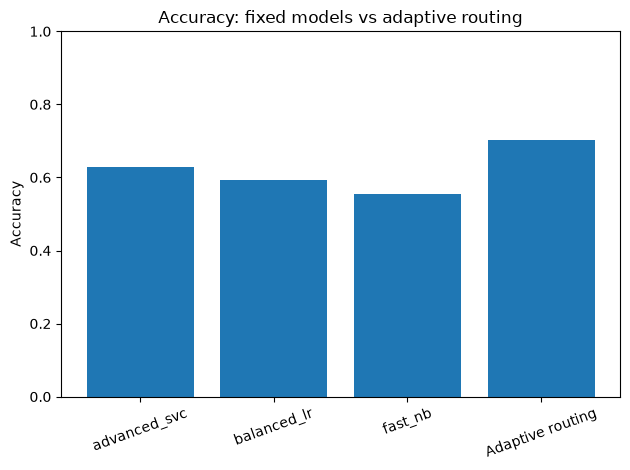

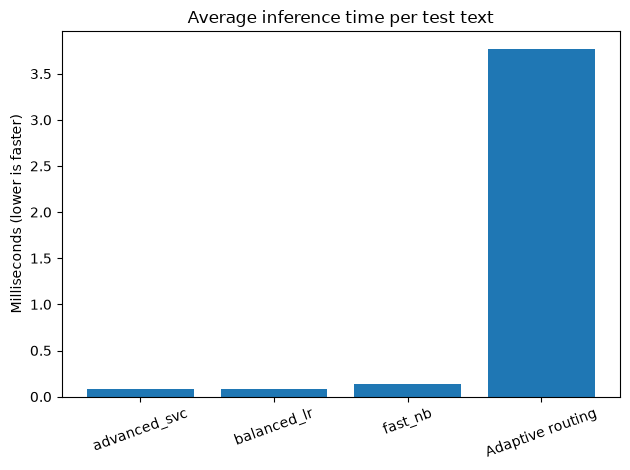

In [10]:
fig, ax = plt.subplots()
ax.bar(comparison["approach"], comparison["accuracy"])
ax.set_title("Accuracy: fixed models vs adaptive routing")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.bar(comparison["approach"], comparison["avg_ms_per_text"])
ax.set_title("Average inference time per test text")
ax.set_ylabel("Milliseconds (lower is faster)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Adaptive routing classification report:
              precision    recall  f1-score   support

       mixed       1.00      0.88      0.93         8
    negative       1.00      0.20      0.33         5
     neutral       1.00      0.25      0.40         4
    positive       0.56      1.00      0.71        10

    accuracy                           0.70        27
   macro avg       0.89      0.58      0.60        27
weighted avg       0.84      0.70      0.66        27



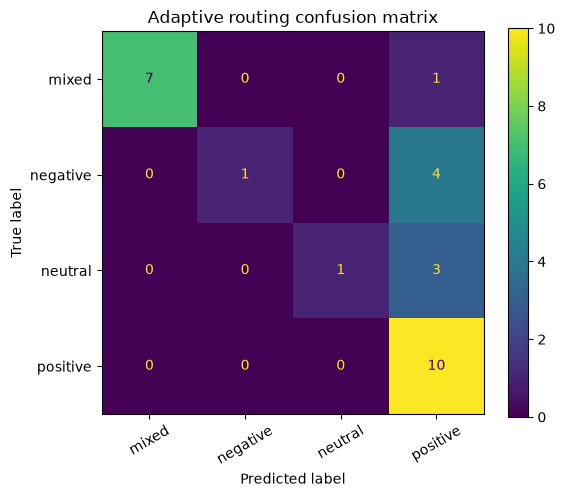

In [11]:
print("Adaptive routing classification report:")
print(classification_report(y_test, adaptive_preds, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, adaptive_preds, ax=ax, xticks_rotation=30)
ax.set_title("Adaptive routing confusion matrix")
plt.tight_layout()
plt.show()

In [12]:
custom_text = "The delivery was late, but the food quality was excellent."
custom_result = adaptive_predict(custom_text)
display(pd.DataFrame([{
    "input_text": custom_result["text"],
    "sentiment": custom_result["sentiment"],
    "confidence": custom_result["confidence"],
    "complexity": custom_result["complexity_score"],
    "model_selected": custom_result["selected_model"],
    "aspects": str(custom_result["aspect_sentiment"]),
    "review_required": custom_result["needs_human_review"]
}]))

,input_text,sentiment,confidence,complexity,model_selected,aspects,review_required
0,"The delivery was late, but the food quality wa...",mixed,0.556,0.48,balanced_lr,"{'delivery': 'negative', 'product_quality': 'p...",False
